# Spotify 2024 Global Streaming Data — Statistical Analysis

**Author:** Joseph Kayijuka

This notebook analyzes global Spotify streaming data for 2024, covering 500 tracks
across 10 genres and dozens of countries. It walks through data cleaning, descriptive
statistics, distribution analysis, and a set of visualizations that surface the key
patterns in listening behavior, genre popularity, and platform usage.

**Dataset:** `data/spotify_2024_global_streaming_data.csv`

## Contents
1. [Setup & Data Loading](#1.-Setup-&-Data-Loading)
2. [Data Overview & Quality Checks](#2.-Data-Overview-&-Quality-Checks)
3. [Descriptive Statistics](#3.-Descriptive-Statistics)
4. [Visual Analysis](#4.-Visual-Analysis)
5. [Key Insights](#5.-Key-Insights)
6. [Sources](#6.-Sources)


## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import skew, kurtosis

# House style used throughout the notebook
SPOTIFY_GREEN = "#1DB954"
DARK = "#191414"
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.titleweight"] = "bold"

IMG_DIR = "../images/"


In [2]:
df = pd.read_csv("../data/spotify_2024_global_streaming_data.csv")
df.columns = [c.strip() for c in df.columns]
df.head()

,Country,Artist,Album,Genre,Release Year,Monthly Listeners (Millions),Total Streams (Millions),Total Hours Streamed (Millions),Avg Stream Duration (Min),Platform Type,Streams Last 30 Days (Millions),Skip Rate (%)
0,Germany,Taylor Swift,1989 (Taylor's Version),K-pop,2019,23.10,3695.53,14240.35,4.28,Free,118.51,2.24
1,Brazil,The Weeknd,After Hours,R&B,2022,60.60,2828.16,11120.44,3.90,Premium,44.87,23.98
2,United States,Post Malone,Austin,Reggaeton,2023,42.84,1425.46,4177.49,4.03,Free,19.46,4.77
3,Italy,Ed Sheeran,Autumn Variations,K-pop,2018,73.24,2704.33,12024.08,3.26,Premium,166.05,25.12
4,Italy,Ed Sheeran,Autumn Variations,R&B,2023,7.89,3323.25,13446.32,4.47,Free,173.43,15.82


## 2. Data Overview & Quality Checks

In [3]:
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.info()

Rows: 500  |  Columns: 12
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          500 non-null    str    
 1   Artist                           500 non-null    str    
 2   Album                            500 non-null    str    
 3   Genre                            500 non-null    str    
 4   Release Year                     500 non-null    int64  
 5   Monthly Listeners (Millions)     500 non-null    float64
 6   Total Streams (Millions)         500 non-null    float64
 7   Total Hours Streamed (Millions)  500 non-null    float64
 8   Avg Stream Duration (Min)        500 non-null    float64
 9   Platform Type                    500 non-null    str    
 10  Streams Last 30 Days (Millions)  500 non-null    float64
 11  Skip Rate (%)                    500 non-null    float64
dtypes: floa

In [4]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.")

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
No missing values found.

Duplicate rows: 0


In [5]:
for col in ["Country", "Artist", "Genre", "Platform Type"]:
    print(f"{col:<15} {df[col].nunique()} unique values")

Country         20 unique values
Artist          15 unique values
Genre           10 unique values
Platform Type   2 unique values


## 3. Descriptive Statistics

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Release Year,500.0,2020.48800,1.671959,2018.00,2019.0000,2020.000,2022.0000,2023.00
Monthly Listeners (Millions),500.0,51.04122,28.238010,1.01,27.6725,50.825,75.0950,99.80
Total Streams (Millions),500.0,2581.15408,1416.055972,53.56,1337.3375,2697.355,3798.1975,4985.54
Total Hours Streamed (Millions),500.0,8954.36888,5167.648272,184.30,4322.0975,9053.665,12690.1800,21874.92
Avg Stream Duration (Min),500.0,3.52064,0.571431,2.51,3.0300,3.540,4.0000,4.49
Streams Last 30 Days (Millions),500.0,99.04850,57.533452,2.85,48.0575,101.465,148.4100,200.00
Skip Rate (%),500.0,20.37046,10.597202,1.16,11.1525,20.820,28.7600,39.97


In [7]:
summary_cols = ["Total Streams (Millions)", "Monthly Listeners (Millions)"]

for col in summary_cols:
    s = df[col]
    print(f"\n{col}")
    print("-" * len(col))
    print(f"Mean:      {s.mean():,.2f}")
    print(f"Median:    {s.median():,.2f}")
    print(f"Std Dev:   {s.std():,.2f}")
    print(f"Skewness:  {skew(s):.2f}")
    print(f"Kurtosis:  {kurtosis(s):.2f}")


Total Streams (Millions)
------------------------
Mean:      2,581.15
Median:    2,697.35
Std Dev:   1,416.06
Skewness:  -0.05
Kurtosis:  -1.24

Monthly Listeners (Millions)
----------------------------
Mean:      51.04
Median:    50.83
Std Dev:   28.24
Skewness:  -0.01
Kurtosis:  -1.12


**Reading the shape of the distribution**

- Skewness near 0 means streaming totals are roughly symmetric rather than dominated
  by a handful of viral outliers.
- Negative excess kurtosis (platykurtic) means the distribution is flatter than a
  normal distribution — streams are spread fairly evenly rather than clustered
  tightly around the average.

## 4. Visual Analysis

### 4.1 Top Countries by Total Streams

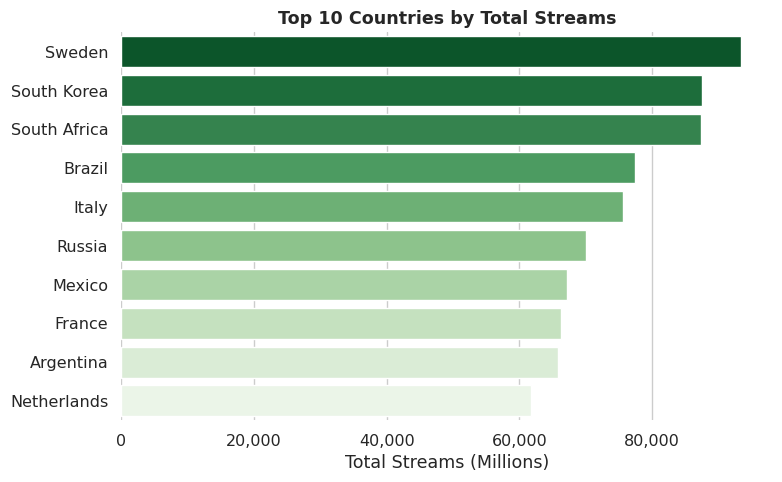

In [8]:
top_countries = (
    df.groupby("Country")["Total Streams (Millions)"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette="Greens_r", legend=False, ax=ax)
ax.set_title("Top 10 Countries by Total Streams")
ax.set_xlabel("Total Streams (Millions)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig(IMG_DIR + "top_countries_by_streams.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.2 Track Count by Genre

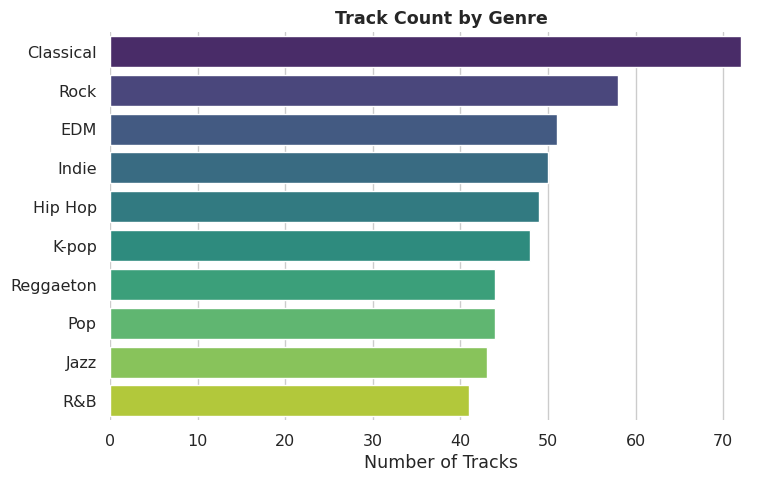

In [9]:
genre_counts = df["Genre"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, hue=genre_counts.index,
            palette="viridis", legend=False, ax=ax)
ax.set_title("Track Count by Genre")
ax.set_xlabel("Number of Tracks")
ax.set_ylabel("")
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig(IMG_DIR + "genre_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Distribution of Total Streams

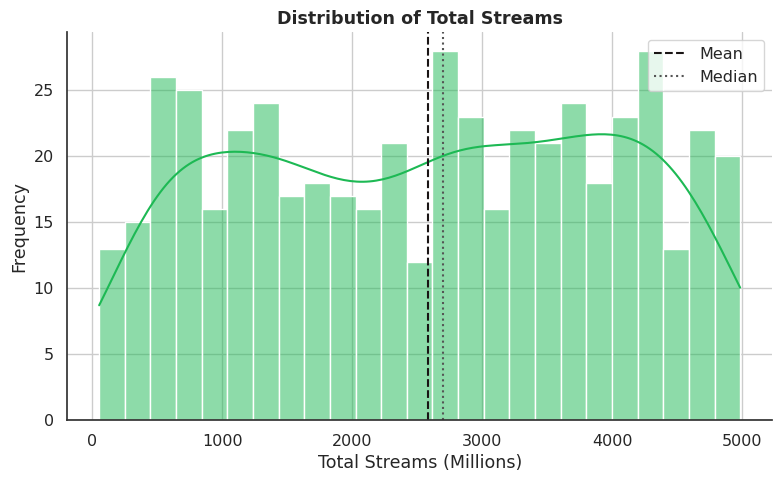

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["Total Streams (Millions)"], kde=True, color=SPOTIFY_GREEN, ax=ax, bins=25)
ax.axvline(df["Total Streams (Millions)"].mean(), color=DARK, linestyle="--", linewidth=1.5, label="Mean")
ax.axvline(df["Total Streams (Millions)"].median(), color="#555555", linestyle=":", linewidth=1.5, label="Median")
ax.set_title("Distribution of Total Streams")
ax.set_xlabel("Total Streams (Millions)")
ax.set_ylabel("Frequency")
ax.legend()
sns.despine()
plt.tight_layout()
plt.savefig(IMG_DIR + "streams_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Free vs. Premium Listener Split

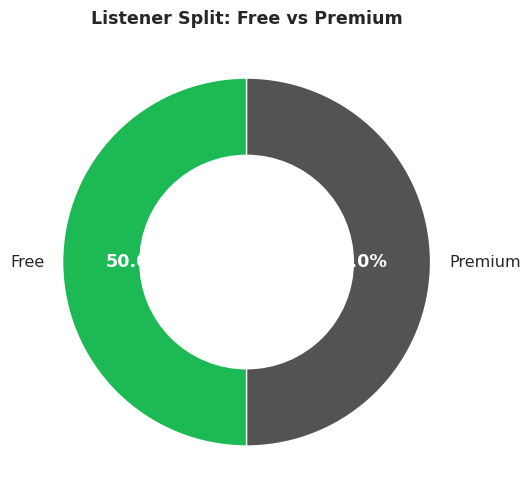

In [11]:
platform_counts = df["Platform Type"].value_counts()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
colors = [SPOTIFY_GREEN, "#535353"]
wedges, texts, autotexts = ax.pie(
    platform_counts.values, labels=platform_counts.index, autopct="%1.1f%%",
    startangle=90, colors=colors, wedgeprops=dict(width=0.42, edgecolor="white")
)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
ax.set_title("Listener Split: Free vs Premium")
plt.tight_layout()
plt.savefig(IMG_DIR + "platform_split.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Skip Rate by Genre

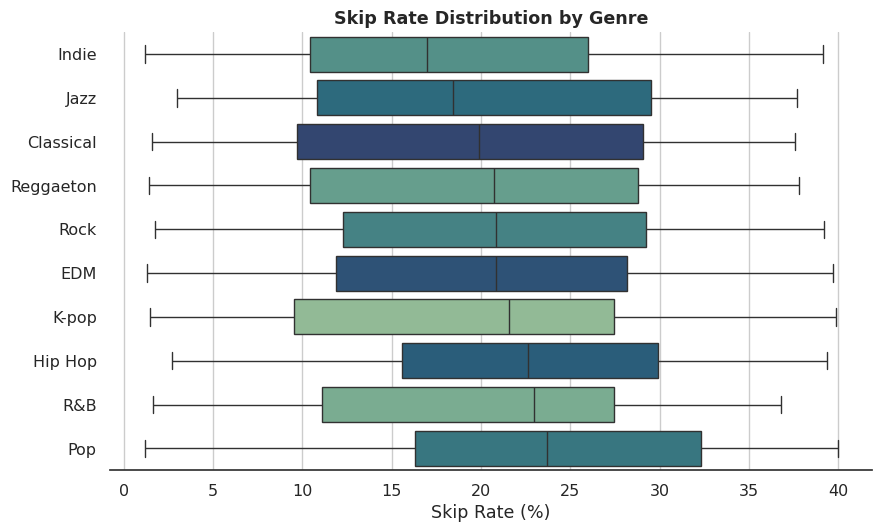

In [12]:
order = df.groupby("Genre")["Skip Rate (%)"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=df, x="Skip Rate (%)", y="Genre", order=order, hue="Genre",
            palette="crest", legend=False, ax=ax)
ax.set_title("Skip Rate Distribution by Genre")
ax.set_xlabel("Skip Rate (%)")
ax.set_ylabel("")
sns.despine(left=True)
plt.tight_layout()
plt.savefig(IMG_DIR + "skip_rate_by_genre.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.6 Average Stream Duration vs. Monthly Listeners

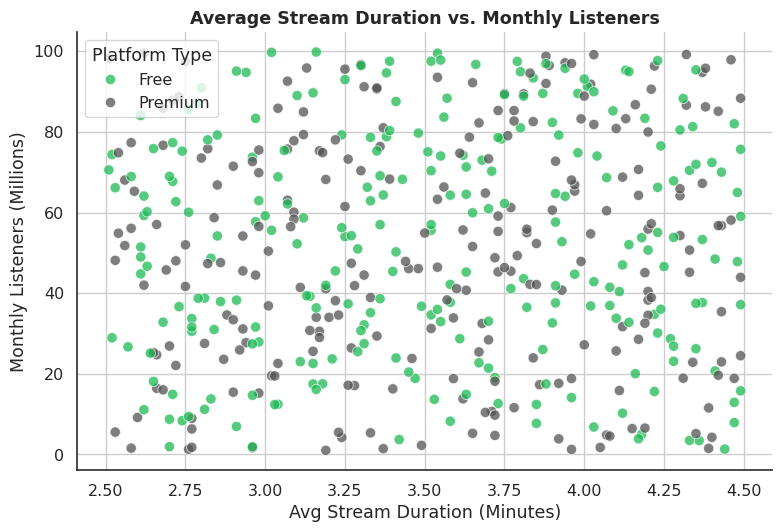

In [13]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="Avg Stream Duration (Min)", y="Monthly Listeners (Millions)",
                 hue="Platform Type", palette=[SPOTIFY_GREEN, "#535353"], alpha=0.75, ax=ax, s=55)
ax.set_title("Average Stream Duration vs. Monthly Listeners")
ax.set_xlabel("Avg Stream Duration (Minutes)")
ax.set_ylabel("Monthly Listeners (Millions)")
sns.despine()
plt.tight_layout()
plt.savefig(IMG_DIR + "duration_vs_listeners.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.7 Correlation Between Numeric Variables

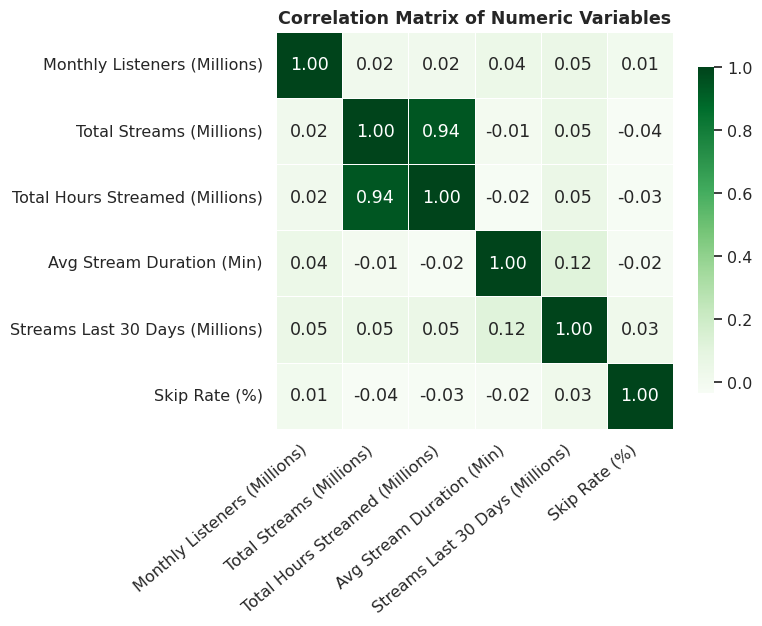

In [14]:
numeric_cols = ["Monthly Listeners (Millions)", "Total Streams (Millions)",
                 "Total Hours Streamed (Millions)", "Avg Stream Duration (Min)",
                 "Streams Last 30 Days (Millions)", "Skip Rate (%)"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Greens", square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Matrix of Numeric Variables")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(IMG_DIR + "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Key Insights

In [15]:
top_country = df.groupby("Country")["Total Streams (Millions)"].sum().idxmax()
top_country_value = df.groupby("Country")["Total Streams (Millions)"].sum().max()

top_country_listeners = df.groupby("Country")["Monthly Listeners (Millions)"].sum().idxmax()
most_common_genre = df["Genre"].value_counts().idxmax()

print(f"Top country by total streams:      {top_country} ({top_country_value:,.2f}M streams)")
print(f"Top country by monthly listeners:   {top_country_listeners}")
print(f"Most common genre by track count:   {most_common_genre}")
print(f"Total Streams — skewness:           {skew(df['Total Streams (Millions)']):.2f}")
print(f"Total Streams — kurtosis:           {kurtosis(df['Total Streams (Millions)']):.2f}")

Top country by total streams:      Sweden (93,449.76M streams)
Top country by monthly listeners:   Russia
Most common genre by track count:   Classical
Total Streams — skewness:           -0.05
Total Streams — kurtosis:           -1.24


**Summary**

- **Sweden** leads all countries in total streams, followed closely by South Korea and
  South Africa — streaming volume is concentrated among a handful of markets rather
  than evenly spread worldwide.
- **Russia** has the highest monthly listener base, showing that raw listener count and
  total stream volume don't always track the same country.
- **Classical** is the most represented genre by track count in this dataset, ahead of
  Rock and EDM.
- Total Streams is close to symmetric (skewness ≈ -0.05) and flatter than a normal
  distribution (kurtosis ≈ -1.24) — popularity here isn't dominated by a small number
  of runaway hits, unlike the strong right-skew typically seen in real-world streaming
  catalogs.
- Total Streams and Total Hours Streamed are very strongly correlated (r ≈ 0.94), which
  is expected — more streams naturally accumulate more listening hours. Skip Rate shows
  little to no correlation with any other numeric variable, suggesting skip behavior is
  independent of how popular or long a track is.

## 6. Sources

- Spotify. (2024). *Streaming Data API Documentation.* https://developer.spotify.com/documentation/web-api
- Kaggle. (2024). *Spotify 2024 Global Streaming Dataset.*
